# Лабораторная работа № 11. Снижение размерности
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** научиться использовать обучаемые алгоритмы снижения размерности.

**Задачи:** повторно использовать код; освоить обучаемые алгоритмы снижения размерности; научиться обосновывать их выбор и анализировать результаты.

**Данные:** wineQualityReds для учебного примера; прежний RCAEval RE2-OB для индивидуального задания.

Работа выполнена по лабораторной № 11 методички *Practicum_AI_Methods.pdf*, с. 109–115.

## 1. Локальный запуск
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. В `environment.yml` добавлен UMAP; Pillow явно указан для чтения изображений. При необходимости обновляем окружение из корня:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Повторный запуск читает сохранённые данные. RCAEval не скачивается заново. Таблицы, координаты, результаты и рисунки сохраняются в папке этой работы внутри `reports/`.

Подключаем библиотеки для файлов, таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
from time import perf_counter
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы машинного обучения.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA, FastICA, TruncatedSVD
from sklearn.manifold import MDS, TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist
import umap

from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from sklearn.base import clone

/home/nik/Desktop/AILabs/.conda/rcaeval-ai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab11'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'umap-learn', 'Pillow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
umap-learn       0.5.12
Pillow           12.3.0
Name: Версия, dtype: object

167

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Методы и смысл карты
PCA сохраняет направления большого разброса; ICA ищет относительно независимые составляющие; TruncatedSVD строит компактное линейное представление. MDS старается сохранить общие расстояния, t-SNE и UMAP — соседство объектов.

Для сравнения используем одни и те же строки и входные признаки. Метки задают **только цвет**, в обучение карт не передаются. Координаты разных методов имеют разные шкалы; поворот или отражение карты сами по себе не меняют соседство.

Определяем шесть методов для карты из двух координат.

In [6]:
def reduction_methods():
    return {
        'PCA': PCA(n_components=2, random_state=SEED),
        'ICA': FastICA(n_components=2, max_iter=2000, tol=0.01, random_state=SEED),
        'TruncatedSVD': TruncatedSVD(n_components=2, random_state=SEED),
        'MDS': MDS(n_components=2, n_init=1, max_iter=300, normalized_stress=True, random_state=SEED),
        't-SNE': TSNE(n_components=2, perplexity=30, max_iter=1000, init='pca', learning_rate='auto', random_state=SEED),
        'UMAP': umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, n_epochs=300, random_state=SEED, n_jobs=1)
    }

Определяем показатели сохранения соседства и расстояний.

In [7]:
def embedding_quality(X, coordinates, labels):
    original_distance = pdist(X)
    map_distance = pdist(coordinates)
    scale = np.dot(original_distance, map_distance) / np.dot(map_distance, map_distance)
    stress = np.sqrt(np.sum((original_distance - scale * map_distance) ** 2)
                     / np.sum(original_distance ** 2))
    return {'trustworthiness': trustworthiness(X, coordinates, n_neighbors=10),
            'stress': float(stress), 'silhouette': silhouette_score(coordinates, labels)}

**Trustworthiness** от 0 до 1 оценивает сохранение локальных соседей, больше — лучше. **Stress** здесь — относительное искажение всех попарных расстояний после подбора одного общего масштаба карты, меньше — лучше. Одна формула применяется ко всем методам.

**Silhouette** от −1 до 1 показывает разделение заданных цветовых групп в новых координатах. Это описание карты с известными метками, а не точность классификатора. Методы могут выигрывать по разным критериям.

Определяем функцию расчёта и сохранения карт.

In [8]:
def compare_embeddings(X, labels, prefix):
    embeddings, rows = {}, []
    for name, method in reduction_methods().items():
        start = perf_counter()
        coordinates = method.fit_transform(X)
        elapsed = perf_counter() - start
        embeddings[name] = coordinates
        rows.append({'method': name, **embedding_quality(X, coordinates, labels), 'seconds': elapsed})
    table = pd.DataFrame(rows)
    table.to_csv(REPORT / f'{prefix}_metrics.csv', index=False)
    np.savez_compressed(REPORT / f'{prefix}_coordinates.npz', **embeddings)
    return embeddings, table

Определяем функцию показа шести карт с одинаковыми метками.

In [9]:
def show_embeddings(embeddings, labels, title, filename):
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (name, coordinates) in zip(axes.flat, embeddings.items()):
        sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=labels,
                        palette='tab10', s=16, alpha=0.7, ax=ax)
        ax.set(title=name, xlabel='Координата 1', ylabel='Координата 2')
        ax.get_legend().remove()
    handles, legend_labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, title='Метка', loc='lower center', ncol=min(5, len(legend_labels)))
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))
    save_show(fig, filename)

## 2. Учебная задача: красные вина
Повторяем методы из ноутбука, указанного на с. 114: PCA, ICA, TruncatedSVD, MDS, t-SNE и UMAP. Цвет показывает три группы KMeans, как в примере. Эти группы найдены алгоритмом, а не являются настоящими сортами вина.

В таблице 11 измерений и оценка `quality`. Оценку качества исключаем из входных признаков: она не нужна для сравнения химических измерений. Для карт берём фиксированную подвыборку 600 строк из исходной таблицы. Это ограничивает время MDS и позволяет сравнивать все методы на одних объектах.

Получаем исходный CSV учебного примера только при отсутствии локальной копии.

In [10]:
wine_path = ROOT / 'data/raw/wine/wineQualityReds.csv'
wine_path.parent.mkdir(parents=True, exist_ok=True)
source_revision = 'a282e5ed90a613dbf4806e1c572240d919164a72'
wine_url = f'https://raw.githubusercontent.com/enikolaev/MMO/{source_revision}/datasets/LabWork10/wineQualityReds.csv'
if not wine_path.exists():
    wine_path.write_bytes(urlopen(wine_url, timeout=60).read())

Читаем таблицу без служебного столбца номеров строк.

In [11]:
wine = pd.read_csv(wine_path, index_col=0)

Показываем строки, размеры и пропуски.

In [12]:
display(wine.head())
print('Размер:', wine.shape)
display(wine.isna().sum().rename('Пропуски'))

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
2,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
3,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
4,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Размер: (1599, 12)


fixed.acidity           0
volatile.acidity        0
citric.acid             0
residual.sugar          0
chlorides               0
free.sulfur.dioxide     0
total.sulfur.dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Name: Пропуски, dtype: int64

Выбираем фиксированные строки и подготавливаем только измерения.

In [13]:
wine_sample = wine.sample(n=600, random_state=SEED)
wine_features = wine_sample.drop(columns='quality')
wine_scaler = StandardScaler()
wine_ready = wine_scaler.fit_transform(wine_features)
wine_clusters = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(wine_ready)
print('Для всех шести карт:', wine_ready.shape)

Для всех шести карт: (600, 11)


Рассчитываем шесть карт и показатели для учебного примера.

In [14]:
wine_maps, wine_metrics = compare_embeddings(wine_ready, wine_clusters, 'wine')
display(wine_metrics.round(3))

,method,trustworthiness,stress,silhouette,seconds
0,PCA,0.841,0.283,0.333,0.002
1,ICA,0.841,0.290,0.331,0.003
2,TruncatedSVD,0.841,0.283,0.333,0.001
3,MDS,0.872,0.231,0.260,1.404
4,t-SNE,0.962,0.411,0.356,2.237
5,UMAP,0.954,0.408,0.320,7.368


Показываем все карты вина с одними и теми же цветами кластеров.

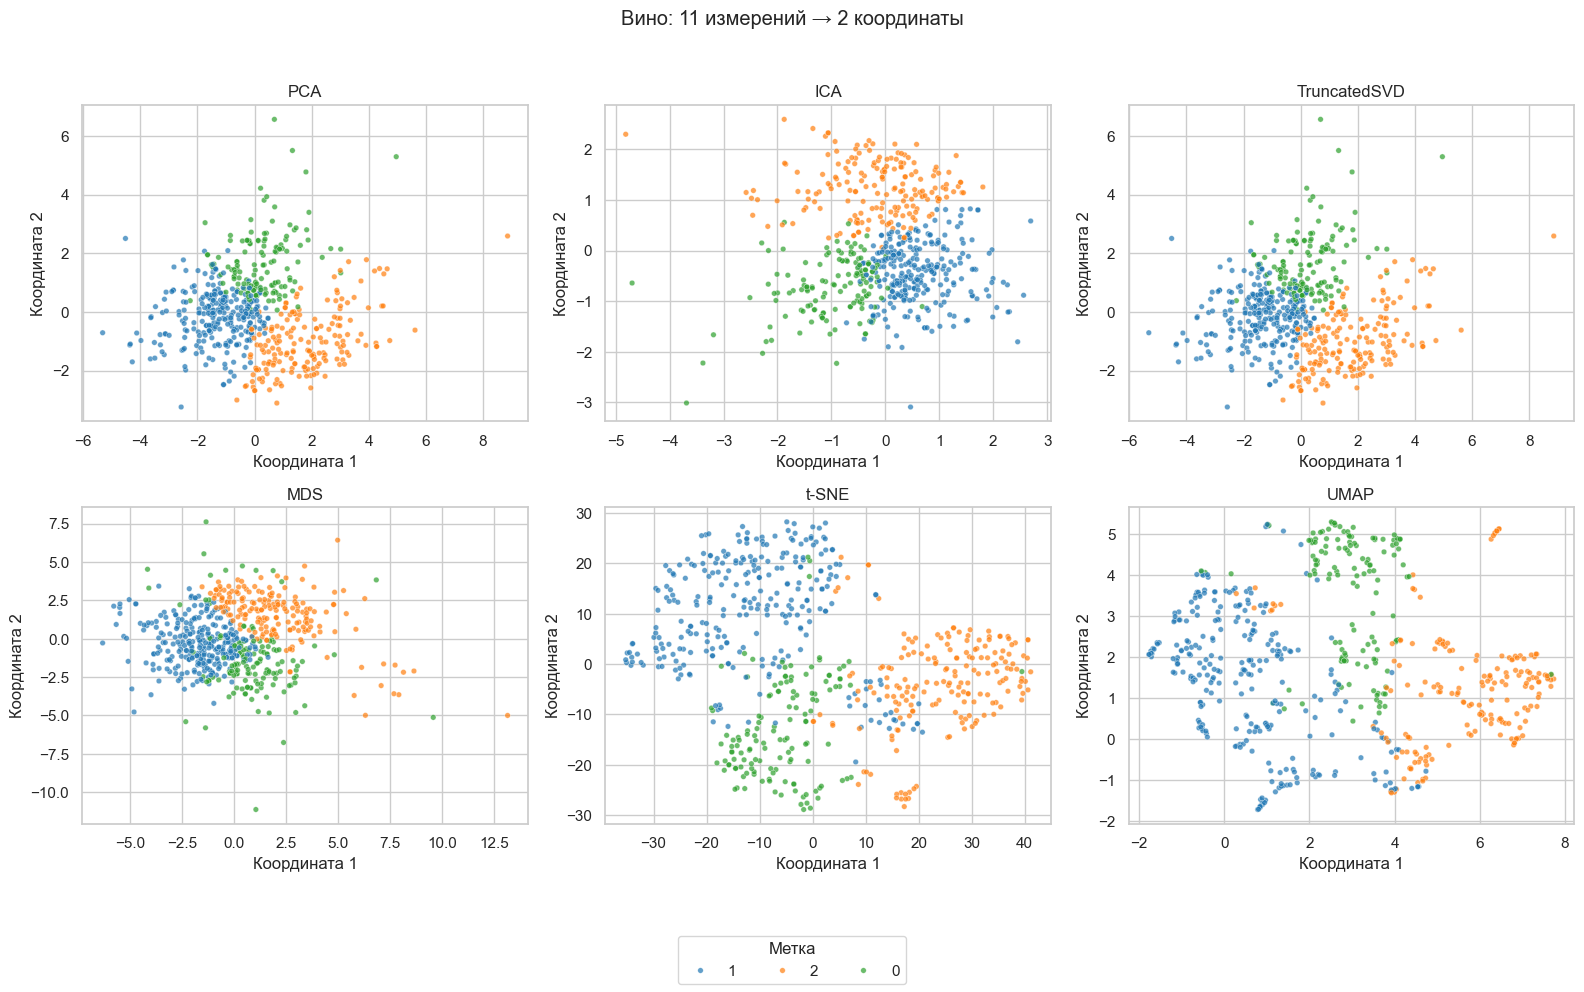

In [15]:
show_embeddings(wine_maps, wine_clusters.astype(str), 'Вино: 11 измерений → 2 координаты', '01_wine_maps.png')

Каждая точка — одна строка исходного набора; её цвет одинаков на всех панелях. Формы групп различаются, поскольку методы сохраняют разные свойства. PCA и TruncatedSVD близки после центрирования данных. ICA может повернуть и растянуть картину. На MDS важнее общие расстояния, на t-SNE и UMAP — локальное соседство. Silhouette здесь относится к группам KMeans, а не к истинным видам вина.

## 3. Индивидуальное задание: сокращение метрик мониторинга

### 3.1. Прежний сценарий RCAEval
Работаем с тем же CPU-экспериментом Online Boutique. Каждая строка исходной таблицы — один момент наблюдения; числовые столбцы — метрики сервисов. Исходный файл не изменяем.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем сохранённое имя сценария.

In [16]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем локальные метрики и время внесения сбоя.

In [17]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Показываем первые строки и размер данных.

In [18]:
display(df.head())
print('Сценарий:', case, '| Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Пропусков:', int(df.isna().sum().sum()))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Строк: 1441 | Метрик: 72
Пропусков: 4


Откладываем целые минутные участки для итоговой проверки.

In [19]:
groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(df, period, groups))
groups_train = groups.iloc[train_idx]
print('Обучение и подбор:', len(train_idx), '| Итоговая проверка:', len(test_idx))

Обучение и подбор: 1141 | Итоговая проверка: 300


Соседние измерения похожи. При подборе и итоговой проверке записи одной минуты сохраняются вместе. Время и метка периода используются для разделения, а не как входные признаки модели. Все результаты относятся к одному эксперименту.

### 3.2. Входные метрики и известный период
Берём все 72 метрики, кроме `time`. Пропуски заполняем медианами обучения. Удаляем признаки, которые постоянны на обучающей части, затем приводим остальные к общему масштабу.

Для сравнения классификации используем знакомую задачу: **0 — до внесения CPU stress, 1 — начиная с внесения**. Эти метки не означают отдельную проверку неисправности каждой строки. Один сценарий не позволяет оценить обнаружение всех других сбоев.

Выделяем признаки и ответы.

In [20]:
features = df.columns.drop('time').tolist()
X, y = df[features].copy(), period
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

Определяем повторно используемую подготовку числовых метрик.

In [21]:
def metrics_preprocessor():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('constant', VarianceThreshold(threshold=0)),
        ('scale', StandardScaler())
    ])

Обучаем подготовку и показываем, сколько постоянных признаков удалено.

In [22]:
prepare = metrics_preprocessor()
train_ready = prepare.fit_transform(X_train)
test_ready = prepare.transform(X_test)
kept_features = np.array(features)[prepare.named_steps['constant'].get_support()]
print('До подготовки:', len(features), '| После удаления постоянных:', train_ready.shape[1])
print('Удалены:', np.array(features)[~prepare.named_steps['constant'].get_support()].tolist())

До подготовки: 72 | После удаления постоянных: 59
Удалены: ['emailservice_diskio', 'recommendationservice_diskio', 'cartservice_socket', 'emailservice_socket', 'frontend_socket', 'paymentservice_socket', 'productcatalogservice_socket', 'recommendationservice_socket', 'redis_socket', 'shippingservice_socket', 'currencyservice_error', 'frontend_error', 'productcatalogservice_error']


Удаление постоянных столбцов — простой отбор: они не различают обучающие строки. Исходные метрики и строки сохраняются в файле. Для каждого разбиения CV далее создаётся новая подготовка, поэтому медианы и список постоянных признаков не берутся из проверочной части.

Показываем доли разброса главных компонент на обучении.

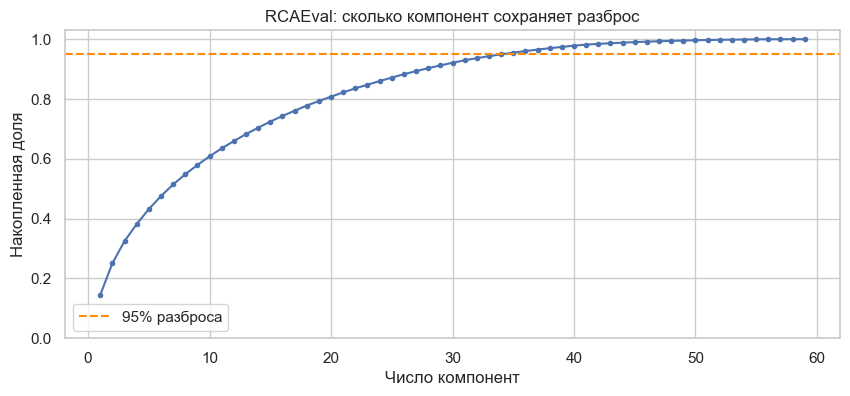

Для 95% разброса нужно компонент: 35


In [23]:
pca_full = PCA(svd_solver='full').fit(train_ready)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
components_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', markersize=3)
ax.axhline(0.95, color='darkorange', linestyle='--', label='95% разброса')
ax.set(title='RCAEval: сколько компонент сохраняет разброс', xlabel='Число компонент', ylabel='Накопленная доля', ylim=(0, 1.03))
ax.legend()
save_show(fig, '02_rca_variance.png')
print('Для 95% разброса нужно компонент:', components_95)

Линия показывает накопленную долю разброса стандартизованных метрик. Значение 0,95 означает сохранение 95% этой вариации, а не 95% правильных ответов. Важный для класса признак может иметь небольшой разброс, поэтому качество классификации проверяем отдельно.

Выбираем 600 обучающих строк для сопоставимых карт.

In [24]:
rng = np.random.default_rng(SEED)
map_positions = np.sort(rng.choice(len(X_train), size=600, replace=False))
map_data = train_ready[map_positions]
map_labels = y_train.iloc[map_positions].to_numpy()
rca_maps, rca_map_metrics = compare_embeddings(map_data, map_labels, 'rca_maps')
display(rca_map_metrics.round(3))

,method,trustworthiness,stress,silhouette,seconds
0,PCA,0.849,0.369,0.306,0.001
1,ICA,0.848,0.370,0.327,0.003
2,TruncatedSVD,0.849,0.369,0.306,0.002
3,MDS,0.880,0.328,0.273,1.438
4,t-SNE,0.994,0.426,0.516,1.726
5,UMAP,0.993,0.441,0.557,0.509


Показываем шесть карт метрик с цветом периода.

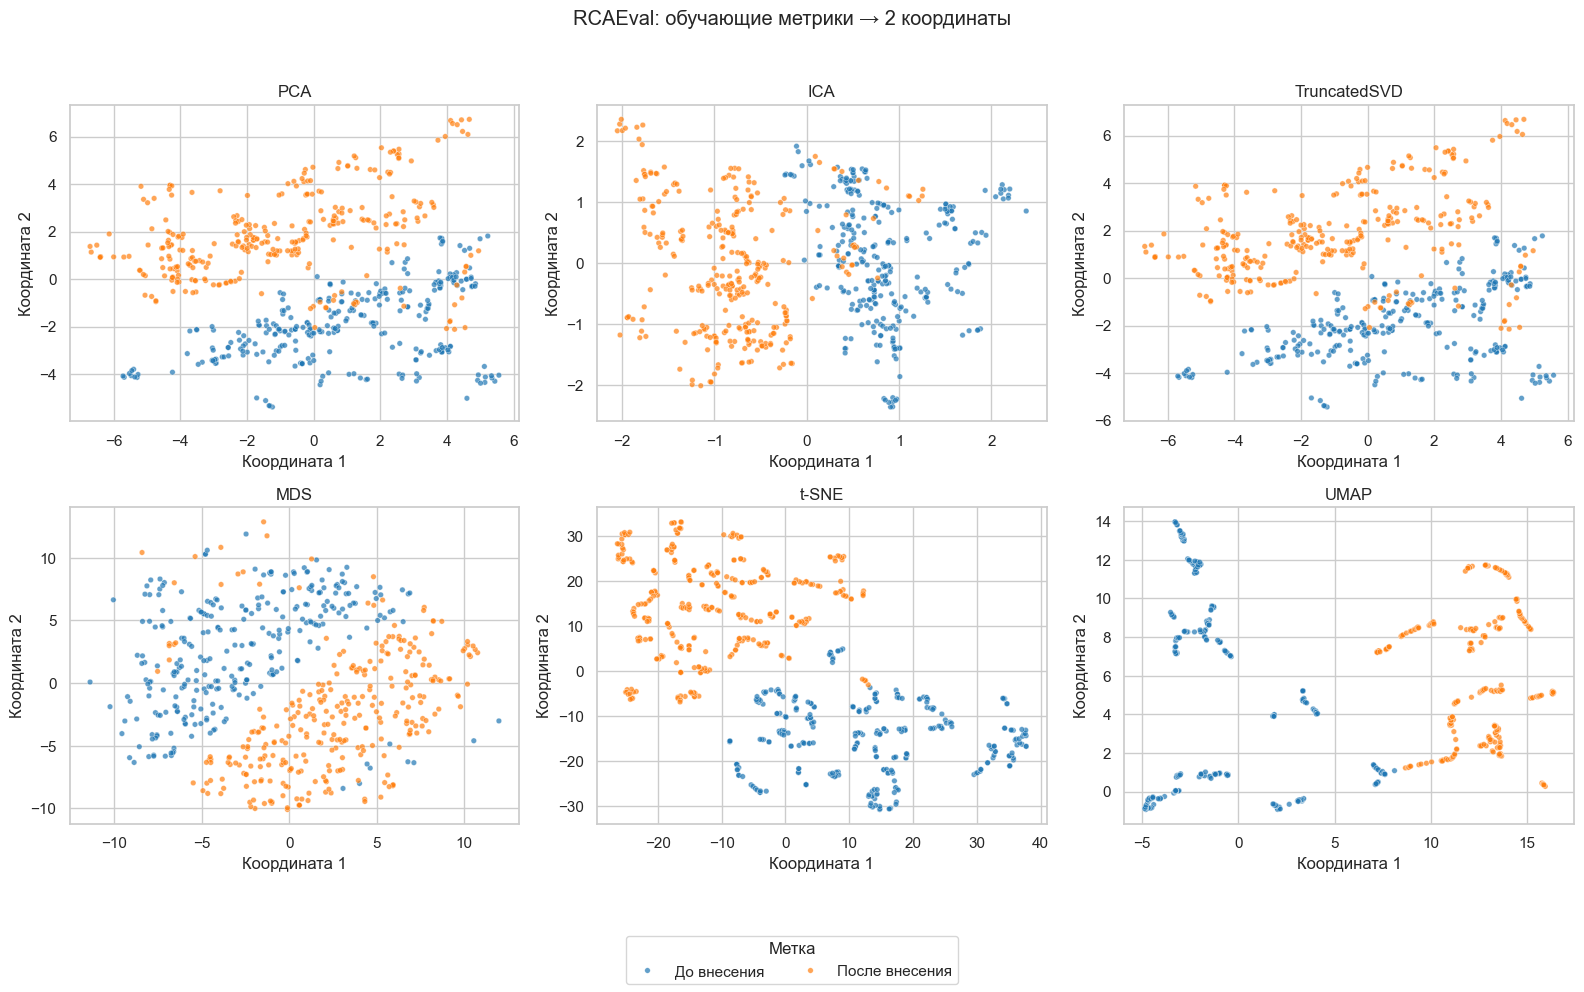

In [25]:
period_names = np.where(map_labels == 0, 'До внесения', 'После внесения')
show_embeddings(rca_maps, period_names, 'RCAEval: обучающие метрики → 2 координаты', '03_rca_maps.png')

Цвет показывает настоящий период, но не участвовал в построении этих шести карт. Разделение периодов может быть заметно даже в двух координатах. Карты построены только для выбранных обучающих строк. Они не являются проверкой классификатора на новых измерениях.

### 3.3. Обучение на исходных и сокращённых признаках
Сравниваем один и тот же LogisticRegression: полный подготовленный набор, PCA с 2 и 5 координатами, PCA с 95% разброса, ICA, TruncatedSVD и UMAP с двумя координатами. После проекции вновь задаём сопоставимый масштаб её координат.

MDS и обычный t-SNE в scikit-learn не имеют `transform` для новых строк. Здесь они используются для карт, а в сравнение обучения включены методы, которые умеют преобразовать отложенные строки без совместного обучения на них.

Задаём варианты представления для классификации.

In [26]:
representations = {
    'Полный набор': 'passthrough',
    'PCA 2': PCA(n_components=2, random_state=SEED),
    'PCA 5': PCA(n_components=5, random_state=SEED),
    'PCA 95%': PCA(n_components=0.95, svd_solver='full'),
    'ICA 2': FastICA(n_components=2, max_iter=2000, tol=0.01, random_state=SEED),
    'TruncatedSVD 2': TruncatedSVD(n_components=2, random_state=SEED),
    'UMAP 2': umap.UMAP(n_components=2, n_neighbors=15, n_epochs=300, random_state=SEED, n_jobs=1)
}

Определяем полный пайплайн классификации.

In [27]:
def classifier_pipeline(reducer):
    return Pipeline([
        ('prepare', metrics_preprocessor()),
        ('reduce', reducer),
        ('projection_scale', StandardScaler()),
        ('classifier', LogisticRegression(C=1, solver='liblinear', max_iter=1000, random_state=SEED))
    ])

Сравниваем представления по пяти частям CV на обучении.

In [28]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, reducer in representations.items():
    scores = cross_validate(classifier_pipeline(reducer), X_train, y_train, groups=groups_train, cv=cv,
                            scoring={'accuracy': 'accuracy', 'AUC': 'roc_auc'})
    cv_rows.append({'representation': name, 'CV_accuracy': scores['test_accuracy'].mean(),
                    'CV_AUC': scores['test_AUC'].mean()})
cv_table = pd.DataFrame(cv_rows)
display(cv_table)

,representation,CV_accuracy,CV_AUC
0,Полный набор,0.985000,0.994722
1,PCA 2,0.877629,0.912205
2,PCA 5,0.980833,0.994523
3,PCA 95%,0.982500,0.997741
4,ICA 2,0.877629,0.912205
5,TruncatedSVD 2,0.877629,0.912205
6,UMAP 2,0.903283,0.944323


Каждый метод подготовки и проекции обучается заново внутри каждой части CV. Так классификатор не получает информацию из проверочных строк. Accuracy — доля правильных классов при стандартном пороге, ROC AUC — качество порядка оценок класса 1. Это разные показатели.

Фиксируем выбор по CV и проверяем все варианты на одинаковых отложенных минутах.

In [29]:
best_name = cv_table.sort_values(['CV_accuracy', 'CV_AUC'], ascending=False).iloc[0].representation
fitted_models, predictions, test_rows = {}, {}, []
for name, reducer in representations.items():
    reducer_copy = reducer if isinstance(reducer, str) else clone(reducer)
    model = classifier_pipeline(reducer_copy).fit(X_train, y_train)
    fitted_models[name] = model
    probabilities = model.predict_proba(X_test)[:, 1]
    predicted = model.predict(X_test)
    predictions[name] = predicted
    width = model[:-1].transform(X_test).shape[1]
    test_rows.append({'representation': name, 'features': width,
                      'test_accuracy': accuracy_score(y_test, predicted), 'test_AUC': roc_auc_score(y_test, probabilities)})
test_table = pd.DataFrame(test_rows)
display(test_table)
print('Выбор только по CV:', best_name)

,representation,features,test_accuracy,test_AUC
0,Полный набор,59,1.000000,1.000000
1,PCA 2,2,0.696667,0.884213
2,PCA 5,5,0.970000,0.999583
3,PCA 95%,35,1.000000,1.000000
4,ICA 2,2,0.696667,0.884213
5,TruncatedSVD 2,2,0.696667,0.884259
6,UMAP 2,2,0.916667,0.967454


Выбор только по CV: Полный набор


При равенстве CV-оценок сохраняется порядок таблицы: это заранее заданное правило. Отложенные минуты одинаковы для всех вариантов. После этой проверки не меняем выбор на основе тестовой таблицы. Число признаков показывает, насколько уменьшился вход классификатора; качество не обязано улучшиться после сокращения.

Строим график точности и числа признаков.

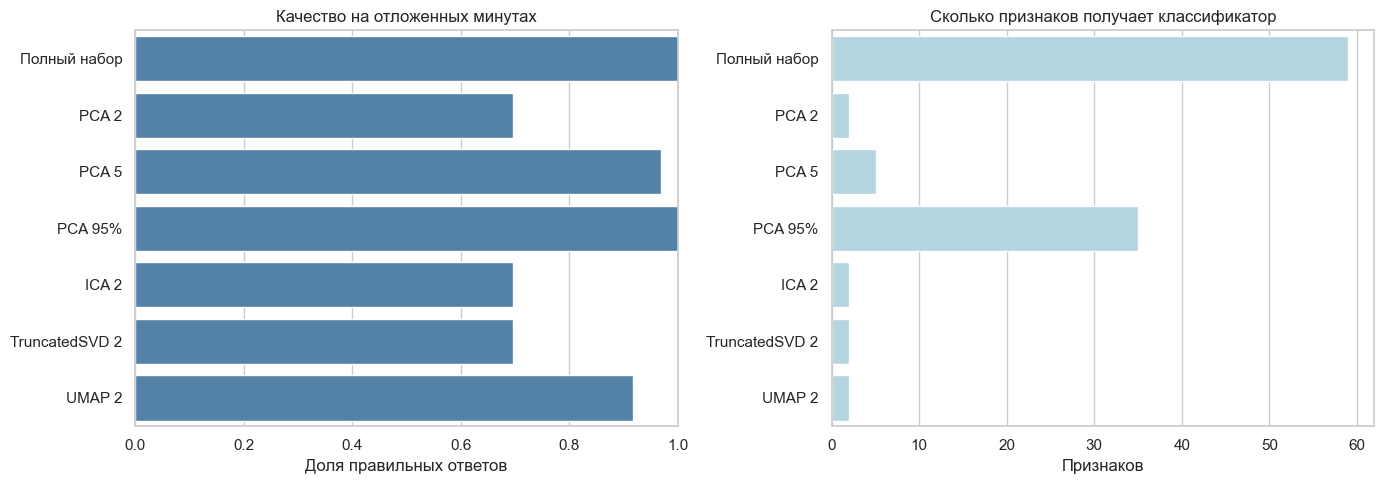

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=test_table, x='test_accuracy', y='representation', color='steelblue', ax=axes[0])
sns.barplot(data=test_table, x='features', y='representation', color='lightblue', ax=axes[1])
axes[0].set(title='Качество на отложенных минутах', xlabel='Доля правильных ответов', ylabel='', xlim=(0, 1))
axes[1].set(title='Сколько признаков получает классификатор', xlabel='Признаков', ylabel='')
fig.tight_layout()
save_show(fig, '04_rca_classification.png')

Левая панель сравнивает правильные ответы, правая — размер входа модели. Уменьшение столбцов полезно, если качество остаётся достаточным для задачи. Это показывает отличие обучения по многомерным метрикам и по компактному представлению, но не оценивает обнаружение новых типов сбоев.

Показываем ошибки варианта, выбранного по CV.

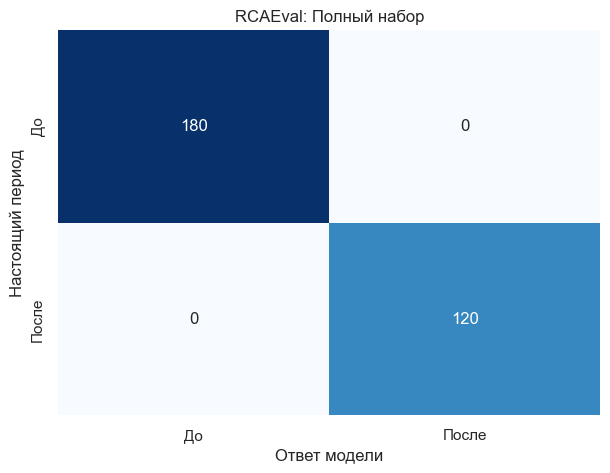

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, predictions[best_name], labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', cbar=False, xticklabels=['До', 'После'], yticklabels=['До', 'После'], ax=ax)
ax.set(title=f'RCAEval: {best_name}', xlabel='Ответ модели', ylabel='Настоящий период')
save_show(fig, '05_rca_confusion.png')

Диагональ содержит правильные ответы, остальные клетки — перепутанные периоды. Это проверка периодов одного CPU-эксперимента. Метка «после» не равна доказанной аварии каждой отдельной строки.

Сохраняем таблицы сравнения и простой текст результата.

In [32]:
cv_table.to_csv(REPORT / 'classification_cv.csv', index=False)
test_table.to_csv(REPORT / 'classification_test.csv', index=False)
pd.DataFrame({'row': X_test.index, 'actual': y_test.to_numpy(), **predictions}).to_csv(REPORT / 'predictions.csv', index=False)
selected_result = test_table.loc[test_table.representation == best_name].iloc[0]
analysis = (f'Научился снижать размерность данных. В RCAEval начал с {len(features)} метрик; '
            f'после удаления постоянных осталось {train_ready.shape[1]}. Для 95% разброса достаточно {components_95} компонент PCA. '
            f'По CV выбран вариант «{best_name}»; на {len(y_test)} отложенных строках accuracy = {selected_result.test_accuracy:.1%}. '
            'Сравнил полный и сокращённые входы одного классификатора. Все шесть методов визуализации рассчитаны на одинаковых строках. '
            'Вывод относится к одному CPU-эксперименту, а не к любым неисправностям.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'case': case, 'original_features': len(features), 'variable_features': train_ready.shape[1],
           'components_95': components_95, 'best_representation': best_name, 'test_rows': len(y_test),
           'test_results': test_table.to_dict('records'), 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
sources = {'wine_url': wine_url, 'source_revision': source_revision, 'rcaeval': selection,
           'sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [wine_path, metrics_path, inject_path]}}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Научился снижать размерность данных. В RCAEval начал с 72 метрик; после удаления постоянных осталось 59. Для 95% разброса достаточно 35 компонент PCA. По CV выбран вариант «Полный набор»; на 300 отложенных строках accuracy = 100.0%. Сравнил полный и сокращённые входы одного классификатора. Все шесть методов визуализации рассчитаны на одинаковых строках. Вывод относится к одному CPU-эксперименту, а не к любым неисправностям.

1191

## 4. Заключение
Научился использовать обучаемые алгоритмы снижения размерности. Освоил PCA, ICA, TruncatedSVD, MDS, t-SNE и UMAP, а также удаление постоянных признаков.

На RCAEval сравнил обучение одного классификатора по полному и сокращённым наборам метрик. Использовал отдельную проверку и обучал преобразования только по обучающим строкам. Увидел, что компактная карта полезна для просмотра, но её качество и качество классификации нужно оценивать отдельно.

## 5. Ответы на контрольные вопросы
**1. Что такое проклятие размерности?**  
Когда признаков много, для надёжного описания данных нужно больше наблюдений. Расстояния становятся менее различимыми, расчёты усложняются, а модель легче запоминает случайные особенности. Снижение размерности уменьшает число признаков, а не обязательно число строк.

**2. Какие основные методы используются?**  
Отбор признаков: VarianceThreshold и статистический отбор. Создание новых признаков: PCA, ICA, TruncatedSVD, факторный анализ и LDA. Для нелинейных карт применяются MDS, Isomap, LLE, t-SNE и UMAP. Не все методы умеют затем преобразовать новые объекты без нового обучения.

**3. Как работает PCA?**  
После подготовки и центрирования данных находит направления с наибольшим разбросом. Затем берёт несколько таких направлений и проецирует на них объекты. Компоненты не коррелируют на обучающих данных, но это не гарантирует их статистической независимости. Доля сохранённого разброса показывает, сколько вариации осталось, а не accuracy модели.

**4. Какова идея t-SNE?**  
Метод старается сохранить близкое соседство объектов при переносе на плоскость. Он сравнивает вероятности соседства в исходных признаках и в новых координатах. На рисунке полезнее рассматривать локальных соседей, чем расстояния между далёкими группами. Размеры групп и их взаимное расположение могут меняться при других параметрах или seed.

## 6. Источники
- Методичка `Practicum_AI_Methods.pdf`, с. 109–115.
- [Учебный ноутбук из методички](https://github.com/enikolaev/MMO/blob/a282e5ed90a613dbf4806e1c572240d919164a72/Lesson%2010.%20Dimensionality%20Reduction/LabWork10.ipynb).
- [RCAEval](https://huggingface.co/datasets/phamquiluan/RCAEval).
- [scikit-learn: снижение размерности](https://scikit-learn.org/1.7/modules/decomposition.html).
- [UMAP: воспроизводимость](https://umap-learn.readthedocs.io/en/latest/reproducibility.html).